In [1]:
import sys
from pathlib import Path
print(sys.executable)
assert Path(sys.prefix).resolve() == Path('/home/miakhlov/course-notebooks/.venv').resolve()

/home/miakhlov/course-notebooks/.venv/bin/python


# ЛР 5. Поиск аналогов и Танимото

**Сущность:** Сравнить ручной бинарный расчёт с молекулярным Morgan и зафиксировать параметры.

**Данные:** molecules.csv; битовые множества {1,2,3}/{2,3,4} — искусственное упражнение.

**Workflow:** Ручная метрика → Morgan → матрица → ранжирование → ограничение.

Перед запуском прочитайте [guideline](../guides/lab05.md) и [теорию](../../Module_theory/Module%205_Fingerprinter_Farmacophore.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [2]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab05"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Вычислите вручную общие и уникальные биты.
2. Сформируйте matrix всех валидных parent с одинаковым Morgan-параметрами.
3. Отранжируйте аналоги этанола; сохраните ID и параметры, не приписывая активность.

Ожидаемое: T=0,5 на множествах; диагональ Morgan=1; симметрия и диапазон [0,1].

[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Normalizer
[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Normalizer
[12:54:06] Running LargestFragmentChooser
[12:54:06] Running Uncharger
[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Normalizer
[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Normalizer
[12:54:06] Running LargestFragmentChooser
[12:54:06] Running Uncharger
[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Normalizer
[12:54:06] Initializing MetalDisconnector
[12:54:06] Running MetalDisconnector
[12:54:06] Initializing Normalizer
[12:54:06] Running Norma

,id,T_to_ethanol
0,M01,1.000000
1,M02,1.000000
9,M12,0.375000
2,M03,0.181818
3,M04,0.181818
7,M10,0.133333
8,M11,0.133333
5,M06,0.066667
4,M05,0.000000
6,M07,0.000000


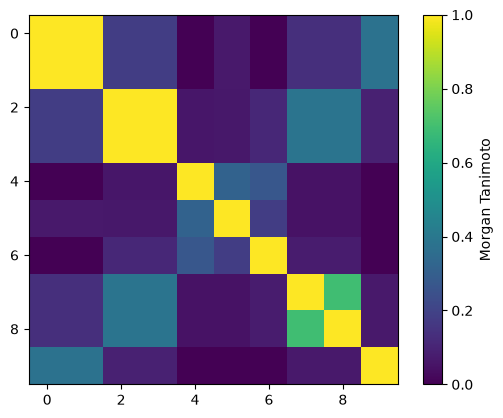

In [3]:
from chemistry import standardize, similarity
from metrics import tanimoto
raw=pd.read_csv(DATA/"molecules.csv",keep_default_na=False)
valid=[]
for row in raw.itertuples():
    try: valid.append((row.id,standardize(row.smiles).parent_smiles))
    except ValueError: pass
matrix=np.array([[similarity(a[1],b[1]) for b in valid] for a in valid])
assert tanimoto({1,2,3},{2,3,4})==0.5
assert np.allclose(matrix,matrix.T) and np.allclose(np.diag(matrix),1)
assert matrix.min()>=0 and matrix.max()<=1
ranking=pd.DataFrame({"id":[x[0] for x in valid],"T_to_ethanol":[similarity("CCO",x[1]) for x in valid]})
display(ranking.sort_values("T_to_ethanol",ascending=False))
pd.DataFrame(matrix,index=[x[0] for x in valid],columns=[x[0] for x in valid]).to_csv(OUT/"tanimoto.csv")
plt.imshow(matrix,vmin=0,vmax=1);plt.colorbar(label="Morgan Tanimoto")
plt.savefig(OUT/"similarity.png",dpi=150);plt.show()
artifact={"radius":2,"fpSize":2048,"includeChirality":True,"molecules":len(valid)}


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [4]:
elapsed = time.perf_counter()-started
run_record = {"lab": 5, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: /home/miakhlov/course-notebooks/Labs/results/lab05/benchmark.json


## 4. Самостоятельная тренировка

1. Сравните радиусы 1 и 3 на новой паре с генератором RDKit.
2. Объясните, почему T=1 не является универсальным доказательством идентичности.
3. Предложите план выбора разнообразных аналогов вместо пяти почти одинаковых.

[Ответы после попытки](../solutions/lab05.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.